In [2]:
import matplotlib.pyplot as plt
import numpy as np
import netket as nk
import netket.experimental as nkx

∣NK⟩ Tip: You can disable these tips by setting export NETKET_NO_TIPS=1 in your .bashrc.

/opt/homebrew/Caskroom/miniforge/base/envs/netket/lib/python3.13/site-packages/netket/graph/common_lattices.py:126: InitializePeriodicLatticeOnSmallLatticeWarning: 
You are attempting to define a lattice with length 2 in dimension 0 using periodic boundary condition.

Lattice with less than two sites in one direction does not support periodic boundary condition.
The behavior of the lattice is equivalent to an open boundary condition in this direction.

To avoid this warning, consider either using a lattice with more than two sites in the direction you want to be periodic,
or define the graph using :class:`~netket.graph.Graph` by adding the edges manually.


-------------------------------------------------------
For more detailed informations, visit the following link:
	 https://netket.readthedocs.io/en/latest/api/_generated/errors/netket.errors.InitializePeriodicLatticeOnSmallLatticeWarning.html
or the list of all common errors and warnings at
	 https://netket.readthedocs.io/en/latest

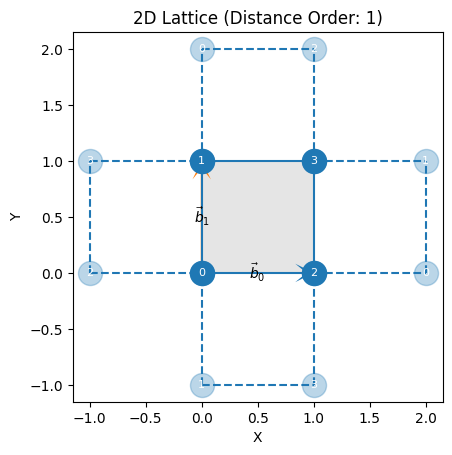

<Axes: title={'center': '2D Lattice (Distance Order: 1)'}, xlabel='X', ylabel='Y'>

In [3]:
# g = nk.graph.Hypercube(3, n_dim=2, pbc=False)
# g = nk.graph.Chain(8, pbc=False)
g = nk.graph.Grid((2,2), pbc=True)
g.draw()

In [5]:
nup, ndn = 1, 1
hi = nk.hilbert.SpinOrbitalFermions(g.n_nodes, 1/2, n_fermions_per_spin=(nup, ndn))
hi 

SpinOrbitalFermions(n_orbitals=4, s=1/2, n_fermions=2, n_fermions_per_spin=(1, 1))

In [6]:
hi.n_states

16

In [61]:
# build properly with correct JW signs
# however, we need to take a hilbert space with any particle number first to build this
hi_tmp = nk.hilbert.SpinOrbitalFermions(g.n_nodes, 1/2)

def cdag(site, *, sz):
    return nk.operator.fermion.create(hi_tmp, site, sz=sz)

# def c(site, spin):
#     return nk.operator.fermion.destroy(hi_tmp, site, spin)

# create the vaccuum
vac_idx = hi_tmp.states_to_numbers(np.zeros((hi.size,)))
vac = np.zeros((hi_tmp.n_states,), dtype=float)
vac[vac_idx] = 1

# here we create a pair on sites 0 and 1, but do it with oeprators to make sure we have the correct JW sign
x = cdag(0, sz=+1) @ cdag(1, sz=-1) + cdag(1, sz=+1) @ cdag(0, sz=-1)
# numbers are the modes, not sites
# NOTE: ordering here: first all sites of up spins, then all sites of down spins (different from Majorana Propagation)
print("Operator = ", x.operator_string())
x = x.to_sparse() @ vac
del vac
x /= np.linalg.norm(x)

# now go to the smaller hilbert space with this amount of particles
nz_idxs = x.nonzero()[0]
nz_states = hi_tmp.numbers_to_states(nz_idxs)
nz_values = x[nz_idxs]
del x
v0 = np.zeros((hi.n_states,), dtype=float)
v0[hi.states_to_numbers(nz_states)] = nz_values
v0 /= np.linalg.norm(v0)

print("Check:\n", hi.numbers_to_states(v0.nonzero()[0]))

v0

Operator =  1.0 [4^ 1^] +
1.0 [5^ 0^]
Check:
 [[0 1 0 0 1 0 0 0]
 [1 0 0 0 0 1 0 0]]


array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        , -0.70710678,  0.        ,  0.        , -0.70710678,
        0.        ])

In [62]:
from exact_dynamics import ExactDynamics

In [63]:
dt = 0.01

U = 4
# can also build custom operators, but we use Hubbard here
ham = nkx.operator.FermiHubbardJax(hi, g, t=1, U=U)

# second order integrator
integrator = nkx.dynamics.Heun(dt)
integrator

/var/folders/_w/9bl3fcts4q18wd3mdb2c3v2r0000gr/T/ipykernel_93602/1329809383.py:5: DeprecationWarning: netket.experimental.operator.FermiHubbardJax is now stable: use netket.operator.FermiHubbardJax
  ham = nkx.operator.FermiHubbardJax(hi, g, t=1, U=U)


RKExplicitSolver(tableau=Heun(order=2/1, n_stages=2, adaptive, fsal=False), dt=0.01, adaptive=False, integrator_parameters=IntegratorParameters(dt=0.01, atol=0.0, rtol=1e-07, dt_limits=(None, 0.1)))

In [64]:
ed = ExactDynamics(hi, ham, v0, integrator)
ed

ExactDynamics(step_count=0, t=0.0)

In [66]:
# indices here are the modes, not sites
# NOTE: see ordering of modes above

obs_up = {
    f"nup_{i}":nk.operator.FermionOperator2ndJax(hi, terms=[f"{i}^ {i}"], weights=[1.0]) for i in range(g.n_nodes)
}
obs_dn = {
    f"ndn_{i}":nk.operator.FermionOperator2ndJax(hi, terms=[f"{g.n_nodes+i}^ {g.n_nodes+i}"], weights=[1.0]) for i in range(0, g.n_nodes)
}

obs = {**obs_up, **obs_dn}
obs["hopping"] = nk.operator.FermionOperator2ndJax(hi, terms=[f"0^ 1", f"1^ 0"], weights=[1.0, 1.0]) 
print(obs["hopping"].operator_string())

1.0 [0^ 1] +
1.0 [1^ 0]


In [67]:
def cb(step_nr, log_data, driver):
    return True

In [ ]:
T = 2
exp_name = f"data/benchmark_TDVP_ED_U{U}"
ed.run(T, out=exp_name, obs=obs, tstops=np.arange(0, T, 0.01))

  0%|          | 0.00/2.00 [00:00<?, ?it/s]

(JsonLog('data/results_TDVP_ED_U4', mode=write, autoflush_cost=0.005)
   Runtime cost:
   	Log:    0.007798910140991211
   	Params: 0.006477832794189453,)

In [69]:
import json
with open(f"{exp_name}.log", "r") as f:
    data = json.load(f)
data

{'hopping': {'iters': [0.0,
   0.01,
   0.02,
   0.03,
   0.04,
   0.05,
   0.06,
   0.06999999999999999,
   0.07999999999999999,
   0.09,
   0.09999999999999999,
   0.11,
   0.12,
   0.13,
   0.13999999999999999,
   0.15,
   0.16,
   0.16999999999999998,
   0.18,
   0.19,
   0.19999999999999998,
   0.21,
   0.22,
   0.22999999999999998,
   0.24,
   0.25,
   0.26,
   0.27,
   0.27999999999999997,
   0.29,
   0.3,
   0.31,
   0.32,
   0.33,
   0.33999999999999997,
   0.35,
   0.36,
   0.37,
   0.38,
   0.39,
   0.4,
   0.41,
   0.42,
   0.43,
   0.44,
   0.45,
   0.46,
   0.47,
   0.48,
   0.49,
   0.5,
   0.51,
   0.52,
   0.53,
   0.54,
   0.55,
   0.56,
   0.57,
   0.58,
   0.59,
   0.6,
   0.61,
   0.62,
   0.63,
   0.64,
   0.65,
   0.66,
   0.67,
   0.68,
   0.69,
   0.7,
   0.71,
   0.72,
   0.73,
   0.74,
   0.75,
   0.76,
   0.77,
   0.78,
   0.79,
   0.8,
   0.81,
   0.82,
   0.83,
   0.84,
   0.85,
   0.86,
   0.87,
   0.88,
   0.89,
   0.9,
   0.91,
   0.92,
   0.93,
   0.94

In [70]:
import pandas as pd

df = []
for k, v in data.items():
    iters = np.array(v["iters"])
    if isinstance(v, dict) and "Mean" in v:
        v = v["Mean"]
    if isinstance(v, dict) and "real" in v:
        v = np.array(v["real"]) + 1j*np.array(v["imag"])
    if isinstance(v, dict) and "value" in v:
        v = np.array(v["value"])
    v = np.array(v)
    print(iters[:3], v[:3], len(iters), len(v))
    _df = pd.DataFrame({"iters":iters, k:v})
    _df = _df.set_index("iters")
    df.append(_df)
df = pd.concat(df, axis=1)
df

[0.   0.01 0.02] [0.       +0.j 0.       +0.j 0.0023972+0.j] 200 200
[0.   0.01 0.02] [0.5       +0.0000000e+00j 0.49995003+0.0000000e+00j
 0.49980005-1.4134642e-21j] 200 200
[0.   0.01 0.02] [0.5       +0.0000000e+00j 0.49995003+0.0000000e+00j
 0.49980005-1.4134642e-21j] 200 200
[0.   0.01 0.02] [0.00000000e+00+0.00000000e+00j 4.99700180e-05+0.00000000e+00j
 1.99945023e-04+3.07403842e-26j] 200 200
[0.   0.01 0.02] [0.00000000e+00+0.00000000e+00j 4.99700180e-05+0.00000000e+00j
 1.99945023e-04+3.07403842e-26j] 200 200
[0.   0.01 0.02] [0.5       +0.0000000e+00j 0.49995003+0.0000000e+00j
 0.49980005-1.4134642e-21j] 200 200
[0.   0.01 0.02] [0.5       +0.0000000e+00j 0.49995003+0.0000000e+00j
 0.49980005-1.4134642e-21j] 200 200
[0.   0.01 0.02] [0.00000000e+00+0.00000000e+00j 4.99700180e-05+0.00000000e+00j
 1.99945023e-04+3.07403842e-26j] 200 200
[0.   0.01 0.02] [0.00000000e+00+0.00000000e+00j 4.99700180e-05+0.00000000e+00j
 1.99945023e-04+3.07403842e-26j] 200 200
[0.   0.01 0.02] [0.   

,hopping,ndn_0,ndn_1,ndn_2,ndn_3,nup_0,nup_1,nup_2,nup_3,t,Generator
iters,,,,,,,,,,,
0.00,0.000000+0.000000j,0.500000+0.000000j,0.500000+0.000000j,0.000000+0.000000j,0.000000+0.000000j,0.500000+0.000000j,0.500000+0.000000j,0.000000+0.000000j,0.000000+0.000000j,0.00,NaN+0.000000j
0.01,0.000000+0.000000j,0.499950+0.000000j,0.499950+0.000000j,0.000050+0.000000j,0.000050+0.000000j,0.499950+0.000000j,0.499950+0.000000j,0.000050+0.000000j,0.000050+0.000000j,0.01,0.001599+0.000000j
0.02,0.002397+0.000000j,0.499800-0.000000j,0.499800-0.000000j,0.000200+0.000000j,0.000200+0.000000j,0.499800-0.000000j,0.499800-0.000000j,0.000200+0.000000j,0.000200+0.000000j,0.02,0.001600+0.000000j
0.03,0.006382-0.000000j,0.499550+0.000000j,0.499550+0.000000j,0.000450+0.000000j,0.000450+0.000000j,0.499550+0.000000j,0.499550+0.000000j,0.000450+0.000000j,0.000450+0.000000j,0.03,0.001602+0.000000j
0.04,0.011934+0.000000j,0.499200+0.000000j,0.499200+0.000000j,0.000800+0.000000j,0.000800+0.000000j,0.499200+0.000000j,0.499200+0.000000j,0.000800+0.000000j,0.000800+0.000000j,0.04,0.001603-0.000000j
...,...,...,...,...,...,...,...,...,...,...,...
1.95,0.058292+0.000000j,0.236592-0.000000j,0.236592-0.000000j,0.263408+0.000000j,0.263408+0.000000j,0.236592-0.000000j,0.236592-0.000000j,0.263408+0.000000j,0.263408+0.000000j,1.95,0.001879+0.000000j
1.96,0.054468+0.000000j,0.237809+0.000000j,0.237809+0.000000j,0.262191+0.000000j,0.262191+0.000000j,0.237809+0.000000j,0.237809+0.000000j,0.262191+0.000000j,0.262191+0.000000j,1.96,0.001881-0.000000j
1.97,0.050921-0.000000j,0.239035-0.000000j,0.239035-0.000000j,0.260965+0.000000j,0.260965+0.000000j,0.239035+0.000000j,0.239035+0.000000j,0.260965+0.000000j,0.260965+0.000000j,1.97,0.001882-0.000000j


In [14]:
df.to_csv(f"{exp_name}.csv")